# 02 · Três métodos de seleção e votação de features

**Regra de votação (fixada no `config.yaml` antes da comparação):**

1. Cada método ranqueia os atributos originais e aprova o **top 8**.
2. Um atributo é **eleito** se receber **pelo menos 2 dos 3 votos**.
3. Se forem eleitos menos de **6**, o conjunto é completado pelos atributos com **menor soma de rankings**.
4. Empates são ordenados pela soma de rankings.

| Método | Como mede a importância | Agregação das colunas one-hot |
|---|---|---|
| SelectKBest (informação mútua) | Dependência estatística com o alvo, inclusive não linear | maior escore da variável |
| Importância por Random Forest | Redução média de impureza nas árvores | soma das colunas |
| RFE com Regressão Logística | Ordem de eliminação recursiva | coluna que sobreviveu mais |

A seleção é ajustada **só no treino**. Na competição (notebook 03), ela é refeita dentro de cada fold da validação cruzada.

In [1]:
import os, sys, warnings
from pathlib import Path
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore", category=UserWarning)
# Localiza a raiz do repositório e torna o pacote src importável
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.utils import carregar_config, configurar_mlflow, ler_contexto, atualizar_contexto, tags_ciclo, caminho, salvar_json
cfg = carregar_config()
pd.set_option("display.width", 160)

In [2]:
from src.features import VotingSelector
from src.preprocessamento import separar_xy

ctx = ler_contexto(cfg)
treino = pd.read_csv(caminho(cfg["dados"]["processed_dir"]) / "treino.csv")
X_tr, y_tr = separar_xy(treino, cfg)
print(ctx["cycle_id"], ctx["data_version"], "| treino:", X_tr.shape)

c008-20261123-2238 v008-7803f4a3 | treino: (29058, 22)


In [3]:
f = cfg["features"]
seletor = VotingSelector(f["top_k"], f["votos_minimos"], f["min_features"], cfg["projeto"]["seed"]).fit(X_tr, y_tr)
votos = seletor.tabela_votos_
eleitas = seletor.features_eleitas_
display(votos[["feature", "rank_selectkbest", "rank_random_forest", "rank_rfe",
               "voto_selectkbest", "voto_random_forest", "voto_rfe", "votos", "soma_rankings", "eleita"]])
print(f"\nFeatures eleitas ({len(eleitas)}):", eleitas)

,feature,rank_selectkbest,rank_random_forest,rank_rfe,voto_selectkbest,voto_random_forest,voto_rfe,votos,soma_rankings,eleita
0,euribor3m,1,2,2,1,1,1,3,5,True
1,emp.var.rate,5,3,1,1,1,1,3,9,True
2,cons.price.idx,4,7,2,1,1,1,3,13,True
3,month,12,6,2,0,1,1,2,20,True
4,nr.employed,3,1,16,1,1,0,2,20,True
5,contact,11,8,2,0,1,1,2,21,True
6,poutcome,7,4,10,1,1,0,2,21,True
7,cons.conf.idx,2,5,17,1,1,0,2,24,True
8,contatado_antes,6,9,10,1,0,0,1,25,False
9,job,16,11,7,0,0,1,1,34,False



Features eleitas (8): ['euribor3m', 'emp.var.rate', 'cons.price.idx', 'month', 'nr.employed', 'contact', 'poutcome', 'cons.conf.idx']


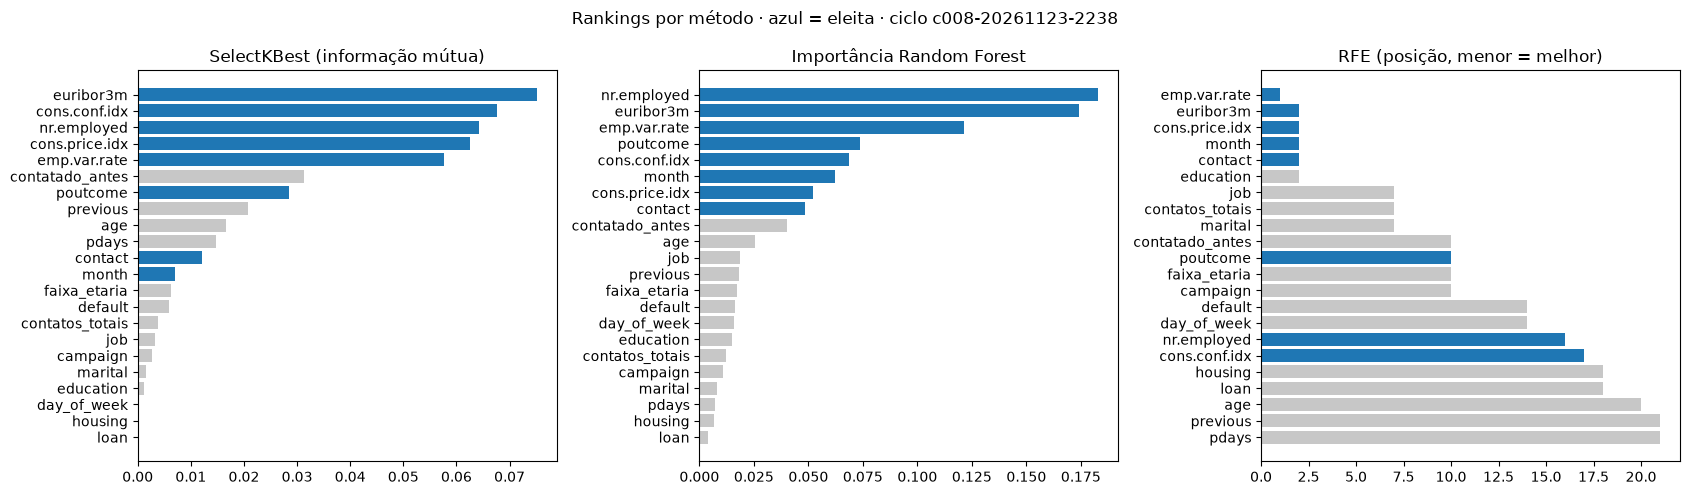

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, col, titulo in [(ax[0], "selectkbest_score", "SelectKBest (informação mútua)"),
                        (ax[1], "random_forest_importance", "Importância Random Forest"),
                        (ax[2], "rank_rfe", "RFE (posição, menor = melhor)")]:
    d = votos.sort_values(col, ascending=(col == "rank_rfe"))
    a.barh(d["feature"], d[col], color=np.where(d["eleita"], "#1f77b4", "#c7c7c7"))
    a.invert_yaxis(); a.set_title(titulo)
fig.suptitle(f"Rankings por método · azul = eleita · ciclo {ctx['cycle_id']}")
plt.tight_layout()
fig_path = caminho(cfg["dados"]["state_dir"]) / "rankings_features.png"
plt.savefig(fig_path, dpi=110); plt.show()

In [5]:
mlflow = configurar_mlflow(cfg)
with mlflow.start_run(run_name=f"{ctx['cycle_id']}_02_votacao", tags=tags_ciclo(ctx, "02_votacao")) as run:
    mlflow.log_params({"metodos": ",".join(f["metodos"]), "top_k": f["top_k"], "votos_minimos": f["votos_minimos"],
                       "min_features": f["min_features"], "desempate": f["desempate"],
                       "regra_votacao": f">= {f['votos_minimos']} de 3 votos (top {f['top_k']} por método)",
                       "features_eleitas": ",".join(eleitas)})
    mlflow.log_metric("n_features_eleitas", len(eleitas))
    mlflow.log_table(votos, "tabela_votos.json")
    mlflow.log_artifact(str(fig_path))
    mlflow.set_tag("features_eleitas", ",".join(eleitas))
    run_id = run.info.run_id

salvar_json({"cycle_id": ctx["cycle_id"], "features_eleitas": eleitas, "tabela_votos": votos.to_dict("records")},
            caminho(cfg["dados"]["state_dir"]) / "votacao_ciclo.json")
atualizar_contexto(cfg, features_eleitas=eleitas, run_votacao=run_id)
print("Votação registrada:", run_id)

Votação registrada: b64d2f5649564ed4aeffcc17dbca1e1e
